In [1]:
from __future__ import annotations

# -----------------------------------------------------------------------------
# EDIT THESE VALUES FOR YOUR CLUSTER ALLOCATION
# -----------------------------------------------------------------------------
# USER_NAME is your Linux username / /home folder name.
# VISIBLE_GPUS are the physical GPU IDs assigned to you, comma-separated.
# After CUDA masking, the first listed physical GPU becomes cuda:0 in this notebook.
# SGLANG_PHYSICAL_GPU is the physical GPU reserved for the SGLang AV server.
USER_NAME = "kaylee"
VISIBLE_GPUS = "0, 1, 2, 3"
SGLANG_PHYSICAL_GPU = "1,2"
LOCAL_DEVICE = "cuda:0"
# -----------------------------------------------------------------------------

# Run this notebook from a fresh kernel. CUDA_VISIBLE_DEVICES must be set before
# importing torch, so this setup cell intentionally defines paths/GPUs first.
import os
from pathlib import Path

## Experiment Overview

All experiments share one AV server and use the same target tokenizer/model state where possible. The notebook deliberately unloads the 27B target before loading the AR, then reloads the target for introspection, so the full target and AR do not coexist on the notebook GPU.

Results are printed and displayed near the cells that produce them. Round-trip and paraphrasing summaries are also written beneath the configurable experiment output root; introspection and zero-vector results remain notebook-only.

In [2]:
HOME = Path("/home") / USER_NAME
NLA_REPO = Path(os.environ.get("NLA_REPO", HOME / "natural_language_autoencoders"))
SGLANG_REPO = Path(os.environ.get("SGLANG_REPO", HOME / "sglang"))
VENV_PYTHON = Path(os.environ.get("NLA_VENV_PYTHON", NLA_REPO / ".venv/bin/python"))
HF_CACHE = Path(os.environ.get("HF_HOME", HOME / ".cache/huggingface"))
ROOT = Path(os.environ.get("NLA_EXPERIMENT_ROOT", HOME / "experiments/nla_experiments"))
LIBNUMA_DIR = Path(
    os.environ.get(
        "NLA_LIBNUMA_DIR", NLA_REPO / "vendor/libnuma/usr/lib/x86_64-linux-gnu"
    )
)
PYTHON_INCLUDE_DIRS = [
    Path(
        os.environ.get(
            "NLA_PYTHON_INCLUDE",
            NLA_REPO / "vendor/python3.10-dev/usr/include/python3.10",
        )
    ),
    Path(
        os.environ.get(
            "NLA_PYTHON_MULTIARCH_INCLUDE",
            NLA_REPO / "vendor/python3.10-dev/usr/include",
        )
    ),
]
ROOT.mkdir(parents=True, exist_ok=True)


os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = VISIBLE_GPUS
os.environ["HF_HOME"] = str(HF_CACHE)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"
if LIBNUMA_DIR.exists():
    os.environ["LD_LIBRARY_PATH"] = (
        f"{LIBNUMA_DIR}:{os.environ.get('LD_LIBRARY_PATH', '')}"
    )
_existing_cpath = os.environ.get("CPATH", "")
_include_paths = [str(path) for path in PYTHON_INCLUDE_DIRS if path.exists()]
if _include_paths:
    os.environ["CPATH"] = ":".join([*_include_paths, _existing_cpath])

import gc
import math
import random
import re
import subprocess
import time
from contextlib import contextmanager
from typing import Any

import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from huggingface_hub import snapshot_download
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
import math
from nla.schema import normalize_activation

# Local NLA inference helpers from the released repo.
import sys

sys.path.insert(0, str(NLA_REPO))
from nla_inference import NLAClient, NLACritic

TARGET_MODEL = "google/gemma-3-12b-it"
ACTOR_REPO_ID = os.environ.get("NLA_ACTOR_DIR", "kitft/nla-gemma3-12b-L32-av")
AR_REPO_ID = os.environ.get("NLA_AR_DIR", "kitft/nla-gemma3-12b-L32-ar")
SGLANG_URL = os.environ.get("SGLANG_URL", "http://127.0.0.1:30000")
SGLANG_LOG = Path.home() / "logs" / "sglang_av_server.log"
SGLANG_LOG.parent.mkdir(parents=True, exist_ok=True)
LAYER_INDEX = 32
DEVICE = LOCAL_DEVICE
SEED = 1234
N_EXAMPLES = 200


def resolve_checkpoint(path_or_repo_id: str) -> str:
    """Return a local checkpoint path with nla_meta.yaml available."""
    candidate = Path(path_or_repo_id).expanduser()
    if candidate.exists():
        assert (
            candidate / "nla_meta.yaml"
        ).exists(), f"Missing nla_meta.yaml in {candidate}"
        return str(candidate)
    local_path = Path(snapshot_download(repo_id=path_or_repo_id))
    assert (
        local_path / "nla_meta.yaml"
    ).exists(), f"Missing nla_meta.yaml in downloaded snapshot {local_path}"
    return str(local_path)


ACTOR_DIR = resolve_checkpoint(ACTOR_REPO_ID)
AR_DIR = resolve_checkpoint(AR_REPO_ID)

assert NLA_REPO.exists(), f"Missing NLA repo: {NLA_REPO}"
assert SGLANG_REPO.exists(), f"Missing patched SGLang checkout: {SGLANG_REPO}"
assert VENV_PYTHON.exists(), f"Missing NLA venv Python: {VENV_PYTHON}"

print("home:", HOME)
print("NLA repo:", NLA_REPO)
print("SGLang checkout:", SGLANG_REPO)
print("HF cache:", HF_CACHE)
print("experiment output:", ROOT)
print("vendored libnuma:", LIBNUMA_DIR if LIBNUMA_DIR.exists() else "not found")
print("vendored Python includes:", [p for p in PYTHON_INCLUDE_DIRS if p.exists()])
print("visible physical GPUs:", VISIBLE_GPUS)
print("SGLang physical GPU:", SGLANG_PHYSICAL_GPU)
print("notebook device:", DEVICE)
print("actor checkpoint:", ACTOR_DIR)
print("AR checkpoint:", AR_DIR)
print(torch.__version__, torch.cuda.is_available())
if torch.cuda.is_available():
    print("visible cuda devices:", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(f"cuda:{i}", torch.cuda.get_device_name(i))

UV_PYTHON_INCLUDE = "/home/kaylee/.local/share/uv/python/cpython-3.10.20-linux-x86_64-gnu/include/python3.10"
assert os.path.exists(os.path.join(UV_PYTHON_INCLUDE, "Python.h")), "Python.h not found at that path"

os.environ["CPATH"] = f"{UV_PYTHON_INCLUDE}:{os.environ.get('CPATH', '')}"
print("CPATH now:", os.environ["CPATH"])

REAL_LIBNUMA_DIR = "/home/kaylee/.local/lib"
assert os.path.exists(os.path.join(REAL_LIBNUMA_DIR, "libnuma.so.1")), "libnuma.so.1 not found there"

os.environ["LD_LIBRARY_PATH"] = f"{REAL_LIBNUMA_DIR}:{os.environ.get('LD_LIBRARY_PATH', '')}"
print("LD_LIBRARY_PATH now:", os.environ["LD_LIBRARY_PATH"])

# !rm -rf ~/.triton/cache

print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH"))
print("CPATH:", os.environ.get("CPATH"))

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

home: /home/kaylee
NLA repo: /home/kaylee/natural_language_autoencoders
SGLang checkout: /home/kaylee/sglang
HF cache: /home/kaylee/.cache/huggingface
experiment output: /home/kaylee/experiments/nla_experiments
vendored libnuma: not found
vendored Python includes: []
visible physical GPUs: 0, 1, 2, 3
SGLang physical GPU: 1,2
notebook device: cuda:0
actor checkpoint: /home/kaylee/.cache/huggingface/hub/models--kitft--nla-gemma3-12b-L32-av/snapshots/7aec22599e8a9cd533564868999b443fcc963cf4
AR checkpoint: /home/kaylee/.cache/huggingface/hub/models--kitft--nla-gemma3-12b-L32-ar/snapshots/3d6901d8243182d642af9dea452ca91549a94615
2.9.1+cu128 True
visible cuda devices: 4
cuda:0 NVIDIA A40
cuda:1 NVIDIA A40
cuda:2 NVIDIA A40
cuda:3 NVIDIA A40
CPATH now: /home/kaylee/.local/share/uv/python/cpython-3.10.20-linux-x86_64-gnu/include/python3.10:
LD_LIBRARY_PATH now: /home/kaylee/.local/lib:/home/kaylee/.local/lib:
LD_LIBRARY_PATH: /home/kaylee/.local/lib:/home/kaylee/.local/lib:
CPATH: /home/kaylee

## Start The AV Server

The AV uses SGLang because the checkpoint expects `input_embeds` injection. This notebook launches the patched editable SGLang checkout through the NLA `.venv`, pinned to the physical GPU chosen in the setup cell.



In [3]:
def launch_sglang_actor() -> subprocess.Popen:
    env = os.environ.copy()
    env["HF_HOME"] = str(HF_CACHE)
    env["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
    env["CUDA_VISIBLE_DEVICES"] = SGLANG_PHYSICAL_GPU
    env["SGLANG_MIN_NEW_TOKEN_RATIO_FACTOR"] = "1"
    env["PYTHONPATH"] = f"{NLA_REPO}:{env.get('PYTHONPATH', '')}"
    if LIBNUMA_DIR.exists():
        env["LD_LIBRARY_PATH"] = f"{LIBNUMA_DIR}:{env.get('LD_LIBRARY_PATH', '')}"
    include_paths = [str(path) for path in PYTHON_INCLUDE_DIRS if path.exists()]
    if include_paths:
        env["CPATH"] = ":".join([*include_paths, env.get("CPATH", "")])

    cmd = [
        str(VENV_PYTHON),
        "-m",
        "sglang.launch_server",
        "--model-path",
        ACTOR_DIR,
        "--port",
        "30000",
        "--host",
        "127.0.0.1",
        "--tp-size",
        "2",
        "--disable-radix-cache",
        "--mem-fraction-static",
        "0.80",
        "--context-length",
        "512",
        "--attention-backend",
        "triton",
        "--disable-cuda-graph",
        "--trust-remote-code",
        "--log-level",
        "warning",
    ]
    print("Launching SGLang on physical GPU", SGLANG_PHYSICAL_GPU)
    print(" ".join(cmd))
    print("SGLang server logs ->", SGLANG_LOG)
    log_f = open(SGLANG_LOG, "ab", buffering=0)
    return subprocess.Popen(
        cmd, env=env, cwd=str(NLA_REPO), stdout=log_f, stderr=subprocess.STDOUT
    )



def sglang_is_healthy() -> bool:
    import urllib.request

    try:
        urllib.request.urlopen(SGLANG_URL + "/health", timeout=2).read()
        return True
    except Exception:
        return False


def wait_for_sglang(timeout_s: int = 300) -> None:
    deadline = time.time() + timeout_s
    last_error = None
    while time.time() < deadline:
        if sglang_is_healthy():
            print("SGLang is healthy")
            return
        try:
            import urllib.request

            urllib.request.urlopen(SGLANG_URL + "/health", timeout=2).read()
        except Exception as exc:
            last_error = exc
        time.sleep(2)
    raise TimeoutError(f"SGLang did not become healthy: {last_error!r}")


sglang_proc = None
if sglang_is_healthy():
    print("SGLang is already healthy at", SGLANG_URL)
else:
    sglang_proc = launch_sglang_actor()
    wait_for_sglang()

Launching SGLang on physical GPU 1,2
/home/kaylee/natural_language_autoencoders/.venv/bin/python -m sglang.launch_server --model-path /home/kaylee/.cache/huggingface/hub/models--kitft--nla-gemma3-12b-L32-av/snapshots/7aec22599e8a9cd533564868999b443fcc963cf4 --port 30000 --host 127.0.0.1 --tp-size 2 --disable-radix-cache --mem-fraction-static 0.80 --context-length 512 --attention-backend triton --disable-cuda-graph --trust-remote-code --log-level warning
SGLang server logs -> /home/kaylee/logs/sglang_av_server.log
SGLang is healthy


In [4]:
print(sglang_is_healthy())

True


## Experiment Setup

In [5]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

tokenizer = AutoTokenizer.from_pretrained(TARGET_MODEL, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    TARGET_MODEL, torch_dtype=torch.bfloat16, device_map="balanced",
    max_memory={0: "40GiB", 3: "40GiB"},
    trust_remote_code=True, attn_implementation="eager",
).eval()
del model.model.vision_tower
gc.collect()
torch.cuda.empty_cache()
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

In [6]:
print("model" in globals())
if "model" in globals():
    print(model.device if hasattr(model, "device") else next(model.parameters()).device)

True
cuda:0


In [7]:
client = NLAClient(ACTOR_DIR, sglang_url=SGLANG_URL)
critic = NLACritic(AR_DIR, device="cpu", dtype=torch.float32)
print("Target and AV client ready")


[NLAClient] 7aec22599e8a9cd533564868999b443fcc963cf4: d_model=3840 inj_scale=80000.0 embed_scale=61.97 inj_char='㈜'(id=246566)


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Some weights of Gemma3ForCausalLM were not initialized from the model checkpoint at /home/kaylee/.cache/huggingface/hub/models--kitft--nla-gemma3-12b-L32-ar/snapshots/3d6901d8243182d642af9dea452ca91549a94615 and are newly initialized: ['model.norm.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[NLACritic] 33 layers  d_model=3840  mse_scale=61.97
Target and AV client ready


The reconstruction error is
$$
\mathcal{L} = \mathbb{E}_{h_l \sim \mathcal{H}} \mathbb{E}_{z \sim AV(\cdot | h_l)} [||h_l - AR(z)||_2^2]
$$
where $\mathcal{H}$ is the distribution produced by extracting layer $l$ activations from $M$ on a corpus of text. 

The FVE is
$$
1 - \frac{L}{ \mathbb{E}_{h_l \sim \mathcal{H}} ||h_l - \bar{h_l}||^2_2}
$$

In [8]:
def av(h: torch.Tensor) -> str:
    v = h.detach().float().cpu().numpy()
    return client.generate(v, temperature=0.0, max_new_tokens=384, extract_explanation=True)


PARAPHRASE_PROMPT = (
    "Please paraphrase the text provided below, preserving its exact meaning "
    "but expressing it in substantially different words and sentence structure "
    "than the original. Do not simply swap individual words for synonyms -- "
    "restructure the sentence(s) genuinely.\n\n"
    "<text>\n{text}\n</text>\n\n"
    "Include your final paraphrased text in <transformed_text> tags."
)

def ar(text: str) -> torch.Tensor:
    return critic.reconstruct(text)  # raw, unnormalized -- matches h's scale


# --- Patch hook: replace the residual stream at the last prompt token ---
class LastTokenPatcher:
    def __init__(self, patch_vec=None):
        self.patch_vec = patch_vec
        self.captured = None
        self._done = False  # only patch once

    def __call__(self, module, inputs, output):
        hidden = output[0] if isinstance(output, tuple) else output
        # Only act on the initial multi-token prefill pass, not each
        # single-token decode step that follows.
        if hidden.shape[1] > 1 and not self._done:
            self.captured = hidden[0, -1, :].detach().clone()
            if self.patch_vec is not None:
                hidden = hidden.clone()
                hidden[0, -1, :] = self.patch_vec.to(hidden.dtype).to(hidden.device)
            self._done = True
            return (hidden,) + output[1:] if isinstance(output, tuple) else hidden
        return output


def mse_cos_from_reconstruction(h_hat: torch.Tensor, h_orig: torch.Tensor, mse_scale: float):
    """Per-example, norm-matched metrics (for reporting alongside FVE, not used *in* FVE)."""
    pred = h_hat.float()
    gold = h_orig.float().cpu()
    pred_n = pred / pred.norm().clamp_min(1e-12) * mse_scale
    gold_n = gold / gold.norm().clamp_min(1e-12) * mse_scale
    mse = ((pred_n - gold_n) ** 2).mean().item()
    cos = (pred_n @ gold_n / (pred_n.norm() * gold_n.norm())).item()
    return mse, cos


def raw_sq_error(h_hat: torch.Tensor, h_orig: torch.Tensor) -> float:
    """||h_orig - h_hat||^2 on raw, unnormalized activations -- this is what
    the paper's L and FVE are defined over, so it must NOT be norm-rescaled
    the way mse_cos_from_reconstruction's inputs are."""
    assert h_hat.dim() == 1 and h_orig.dim() == 1, f"{h_hat.shape=} {h_orig.shape=}"
    return ((h_orig.float().cpu() - h_hat.float().cpu()) ** 2).sum().item()


def fve(sq_errors: list, h_orig_list: list) -> float:
    """FVE = 1 - E[||h - AR(z)||^2] / E[||h - h_bar||^2], both expectations
    taken over the same sample. h_bar is estimated as the sample mean of
    h_orig_list -- this must be computed over the full run, not per-example."""
    h_stack = torch.stack([h.float().cpu() for h in h_orig_list])  # [N, d]
    h_bar = h_stack.mean(dim=0)
    variance = ((h_stack - h_bar) ** 2).sum(dim=1).mean().item()
    L = sum(sq_errors) / len(sq_errors)
    return 1 - L / variance


def get_layer_module(m, layer_idx):
    return m.model.language_model.layers[layer_idx]

# https://github.com/kitft/natural_language_autoencoders/blob/main/examples/gemma27b_layer41_step6000.txt
VAR_NRM = 0.0579  # Gemma-3-27B / layer-41 predict-the-mean MSE from training set

def fve_nrm(mse_nrm: float) -> float:
    """Fraction of training-set activation variance explained (normalized space)."""
    return 1.0 - float(mse_nrm) / VAR_NRM


def run_with_patch(prompt: str, patch_vec, max_new_tokens=256):
    inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
    patcher = LastTokenPatcher(patch_vec)
    handle = get_layer_module(model, LAYER_INDEX).register_forward_hook(patcher)
    try:
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    finally:
        handle.remove()
    text = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return text, patcher.captured

# Experiment - Intervention on Texts

### Natural Language Intervention

The goal is to intervene on the NLA AV's output text or activations to see if we can force the model the reliably make mistakes on the six tasks presented in the prior experimental setup. Current ideas are

1. Lexical Corruption (do this)
-  Swap $n$ tokens for synonyms

```
Take AV output text (correct verbalization)
Pick n words, flip to antonyms
Feed to reconstructor (or whatever downstream scorer)
Measure % "incorrect" as function of n
Plot n vs. failure rate
```
- Use WordNet antonym sets
- $n$ is a fraction of eligible words, not a raw count
- must be weaker than a paraphrase
- flip from past to future



## New Tasks

We construct a diverse array of over 40 relatively simple tasks to test whether function
vectors can be extracted in diverse settings. To simplify the presentation of our analysis, we focus on
a representative sample of 6 tasks:
- Antonym. Given an input word, generate the word with opposite meaning.
    - Nguyen et al (2017)
- Capitalize. Given an input word, generate the same word with a capital first letter.
    - ChatGPT
- Country-Capital. Given a country name, generate the capital city.
    - ChatGPT
- English-French. Given an English word, generate the French translation of the word.
    - Conneau et al (2017)
- Present-Past. Given a verb in present tense, generate the verb’s simple past inflection.
    - ChatGPT
- Singular-Plural. Given a singular noun, generate its plural inflection
    - ChatGPT


For each task have a plot for number of shots (X axis) and accuracy (y-axis). 

- **`acc_baseline_future`** — no patching at all; plain few-shot ICL runs straight through the model. Since the ICL demos teach present→**past**, this should score correct against the past gold, essentially never against the future gold. It's there purely as a sanity check — if this comes out meaningfully above 0, something's wrong upstream (e.g. your `is_future_match` substring check is too loose, or future/past forms overlap for irregular verbs like "read"/"read"/"will read").

- **`acc_nla_future`** — h is patched with `AR(verbalize(h))`, i.e. full AV→AR round trip with **no text edits at all**. This is your 0-edit reference point: how often does the unmodified round trip spontaneously produce future tense? Should also be near 0 (round-tripping shouldn't change the encoded task) — if it's not, that's evidence the round trip itself is lossy/noisy independent of your intervention, which matters for interpreting everything else.

- **`acc_tense_edit`** — the actual experimental condition: h patched with `AR(edit_n(verbalize(h)))`, where `edit_n` flipped `num_edits` past-tense words to future-tense in the verbalization text. This is your main curve — how well does the number-of-edits intervention drive the model toward future-tense output.

- **`acc_noop_edit`** — same number of edits applied, but each targeted word is swapped for itself (no semantic change) — same round-trip disturbance, same edit count, but nothing tense-related actually changed. This isolates whether `acc_tense_edit`'s pattern is driven by the *content* of your edits (real signal) or just by however much noise get introduced whenever you touch the text and re-encode it (artifact).

**`avg_edits_applied`** isn't an accuracy metric — it's a diagnostic: how many edits were *actually* applied on average vs. `num_edits` requested. Because `apply_future_edits` can only edit as many past-tense words as it finds in the verbalization text, if `explanation` often contains fewer than `num_edits` matchable words, this number will fall short of what you asked for — and your x-axis point would be silently mislabeled (e.g. you think you're testing "4 edits" but the verbalizations only ever had 2 to give you). Always check this against the requested count before trusting a given point on your sweep curve.

In [9]:
"""
Edit-count sweep version of the NLA round-trip eval, targeting present-past.

Instead of sweeping ICL shot count, this sweeps the number of tense-flip
edits applied directly to the AV's text verbalization before reconstruction.
The task's function vector encodes "convert present -> past"; we intervene
on av(h)'s text to push it toward "-> future" and check whether the
patched generation actually flips to future tense.

For each num_edits value, plots accuracy (y-axis) of the patched
generation matching the FUTURE-tense gold (not the past-tense gold used
by the underlying ICL task) for four conditions:
  - baseline:      no patching -- plain few-shot ICL (past-tense, unaffected
                    by num_edits; included as a flat reference line)
  - nla_roundtrip: h patched with AR(verbalize(h)), no text edits
                    (num_edits=0 case; also a flat reference line)
  - tense_edit:    h patched with AR(edit_n(verbalize(h))) -- the main
                    condition being swept
  - noop_edit:     h patched with AR(noop_edit_n(verbalize(h))) -- same
                    number of edits, but substituting each target word for
                    itself (specificity control: isolates degradation from
                    edit *count*/round-trip noise vs. from the tense
                    semantics of the edit itself)

Requires present-past-future.json (input/past/future fields) -- see
present-past-future.json produced earlier. Notebook cells -- paste/import
your existing definitions (av, ar, run_with_patch, LastTokenPatcher,
client, critic, model, tokenizer, DEVICE) before running this, same as
the shot-sweep script.
"""

# %%
import json
import random
import re
import string
from pathlib import Path

from tqdm.auto import tqdm

# EDIT_COUNTS[i] = number of tense-bearing words in the AV's verbalization
# to flip past-tense -> future-tense construction. 0 = pure nla_roundtrip
# (no edits), included so the sweep has its own zero-point rather than
# relying on a separately-computed reference.
# EDIT_COUNTS = [4, 6, 8, 10]
N_PER_CONFIG = 2
MAX_NEW_TOKENS = 512
SEED = 0

DATA_DIR = Path("datasets")
OUT_DIR = Path("/mnt/ssd-1/soar-nla/kaylee")
RESULTS_CACHE = OUT_DIR / "tense_flip_edit_sweep_results.json"
TENSE_DATA_PATH = DATA_DIR / "present-past-future.json"


In [10]:
import json
import random
import re
import string
from pathlib import Path

import torch
from tqdm import tqdm

# --------------------------------------------------------------------------
# Assumed to already exist from earlier notebook cells -- NOT defined in
# this file. If any of these aren't in scope when you run this, that's
# the next "not defined" error to expect:
#
#   tokenizer, model, DEVICE          -- your loaded model + its tokenizer/device
#   LAYER_INDEX                       -- which layer the patch hook attaches to
#   get_layer_module(model, idx)      -- resolves that layer's module
#   LastTokenPatcher(patch_vec)       -- the forward-hook class doing the patch
#   run_with_patch(prompt, patch_vec, max_new_tokens)
#                                      -- generates text under the patch, returns (text, h_orig)
#   av(h), ar(explanation)            -- your NLA verbalizer / reconstructor
#   MAX_NEW_TOKENS, N_PER_CONFIG, SEED, OUT_DIR, TENSE_DATA_PATH
#                                      -- your existing config constants
# --------------------------------------------------------------------------


# %%
# --------------------------------------------------------------------------
# Task registry + generic map loader
# --------------------------------------------------------------------------
#
# Every task is defined by a flat JSON list of records sharing one input
# field and two "answer" fields: the SOURCE task's answer (what the ICL
# demos actually teach) and the TARGET task's answer (what we check the
# intervention pushes the model toward). This is exactly the tense.json
# shape generalized:
#
#   tense:                {"input": present, "past": ..., "future": ...}
#   en-fr -> en-es:        {"english": ...,   "french": ..., "spanish": ...}
#   capitalize -> allcaps: {"input": lower,   "capitalize": ..., "allcaps": ...}
#
# task_map is always built as {source_answer: (input, target_answer)},
# keyed by the SOURCE task's answer -- this matches how the original
# tense_map was keyed by `past` (the source/ICL-taught form), not by
# input. Everything downstream (editable-position search, edit
# application, ICL prompt construction) only ever depends on this shape,
# so it is 100% task-agnostic.

from dataclasses import dataclass


# --------------------------------------------------------------------------
# Forward-pass helpers (task-agnostic -- unchanged from the original, just
# carried over here since they don't belong to any one task)
# --------------------------------------------------------------------------

def get_next_token_logits(prompt: str, patch_vec) -> torch.Tensor:
    """Single forward pass (no generation) with the same patching hook as
    run_with_patch, returning logits for the position right after the
    prompt -- i.e. what the model would generate first. Much cheaper than
    generate() since it's one forward call, not max_new_tokens of them.
    """
    inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
    patcher = LastTokenPatcher(patch_vec)
    handle = get_layer_module(model, LAYER_INDEX).register_forward_hook(patcher)
    try:
        with torch.no_grad():
            out = model(**inputs)
    finally:
        handle.remove()
    return out.logits[0, -1, :]


def gold_token_prob_info(logits: torch.Tensor, gold_text: str, k: int = 5) -> dict:
    """Probability the model assigns to the gold target-task answer's
    first token, plus the top-k most likely tokens for context. Using
    the first token of gold (e.g. 'will' from 'will lend', or the whole
    word for single-word targets like translations/allcaps) since that's
    what's predicted at this position -- the full phrase spans multiple
    generation steps.
    """
    probs = torch.softmax(logits, dim=-1)
    gold_first_word = gold_text.split()[0]
    gold_token_id = tokenizer.encode(" " + gold_first_word, add_special_tokens=False)[0]
    p_gold = probs[gold_token_id].item()

    topk_probs, topk_ids = torch.topk(probs, k)
    topk = [(tokenizer.decode([tid]), p.item()) for tid, p in zip(topk_ids.tolist(), topk_probs)]

    return {
        "p_gold_first_token": p_gold,
        "gold_first_token_str": tokenizer.decode([gold_token_id]),
        "topk": topk,  # list of (token_str, prob) tuples
    }


# %%
# --------------------------------------------------------------------------
# Task registry + generic map loader
# --------------------------------------------------------------------------


@dataclass
class TaskConfig:
    name: str            # short id, used in filenames/plot titles
    data_path: Path      # JSON file with the flat records described above
    input_key: str       # shared input field name
    source_key: str      # field the ICL demos teach (was "past" for tense)
    target_key: str      # field we check the intervention pushes toward (was "future")
    out_dir: Path
    results_cache: Path
    drop_identity: bool = True   # drop records where source or target == input
                                   # (e.g. MUSE dictionary rows with no real
                                   # translation, or single-letter words where
                                   # capitalize == allcaps -- these carry zero
                                   # signal for a "did it switch" check)
    case_sensitive: bool = False  # is_target_match lowercases both sides by
                                   # default (fine for tense/translation, where
                                   # case never carries the task's meaning) --
                                   # MUST be True for capitalize_allcaps, or
                                   # "Platinum" and "PLATINUM" are the same
                                   # string and every prediction "matches"
                                   # regardless of whether it's actually allcaps


TASKS = {
    "tense": TaskConfig(
        name="tense",
        data_path=TENSE_DATA_PATH,
        input_key="input", source_key="past", target_key="future",
        out_dir=OUT_DIR / "tense",
        results_cache=OUT_DIR / "tense" / "results.json",
    ),
    "en_fr_es": TaskConfig(
        name="en_fr_es",
        data_path=Path("datasets/en-fr-es.json"),
        input_key="english", source_key="french", target_key="spanish",
        out_dir=OUT_DIR / "en_fr_es",
        results_cache=OUT_DIR / "en_fr_es" / "results.json",
    ),
    "capitalize_allcaps": TaskConfig(
        name="capitalize_allcaps",
        data_path=Path("datasets/capitalize-allcaps.json"),
        input_key="input", source_key="capitalize", target_key="allcaps",
        out_dir=OUT_DIR / "capitalize_allcaps",
        results_cache=OUT_DIR / "capitalize_allcaps" / "results.json",
        drop_identity=False,  # capitalize/allcaps entries are already curated;
                               # nothing here collides by construction
        case_sensitive=True,  # the task's entire signal IS case -- see above
    ),
}


def load_task_map(cfg: TaskConfig) -> dict:
    """Returns {source_answer: (input, target_answer)}, generalizing
    load_tense_map to any TaskConfig. Optionally drops records where the
    source or target answer is identical to the input, OR where source
    and target are identical to EACH OTHER -- both give zero signal on
    whether an intervention actually changed anything. The source==input
    / target==input case is e.g. MUSE dictionary rows with no real
    translation; the source==target case is different and specific to
    language pairs sharing cognates (en_fr_es: ~16% of French/Spanish
    translations are spelled identically -- "will"->"will"/"will",
    "club"->"club"/"club" -- so editing "the French answer" to "the
    Spanish answer" is a literal no-op for those, not a real edit at all.
    """
    with open(cfg.data_path, encoding="utf-8") as f:
        entries = json.load(f)
    task_map = {}
    n_dropped = 0
    for e in entries:
        inp, src, tgt = e[cfg.input_key], e[cfg.source_key], e[cfg.target_key]
        if cfg.drop_identity and (
            src.lower() == inp.lower() or tgt.lower() == inp.lower() or src.lower() == tgt.lower()
        ):
            n_dropped += 1
            continue
        task_map[src] = (inp, tgt)
    if n_dropped:
        print(f"[{cfg.name}] dropped {n_dropped} identity/degenerate records "
              f"({len(task_map)} usable)")
    return task_map


# Back-compat shim -- old call sites that still say load_tense_map() keep working.
def load_tense_map(path: Path = TENSE_DATA_PATH) -> dict:
    return load_task_map(TASKS["tense"])


# %%
# --------------------------------------------------------------------------
# Editable-position search + edit application (task-agnostic)
# --------------------------------------------------------------------------
#
# Unchanged in substance from the tense-only version -- these two
# functions never actually depended on tense semantics, only on
# `task_map` being a {source_form: (input, target_form)} dict whose keys
# are literal substrings that might appear in the AV's verbalization
# text. Renamed the parameter from `tense_map` to `task_map` for clarity;
# logic is identical.

def find_editable_positions(text: str, task_map: dict) -> list[tuple[int, int, str]]:
    """Finds whole-word, case-insensitive matches of known source-task
    answers (e.g. past-tense forms, French translations, Capitalized
    forms) in `text`. Returns list of (start, end, matched_form) in order
    of appearance. Word-boundary regex avoids matching "read" inside
    "already", or "el" inside "elephant", etc.

    Note: \\b in Python's re module is Unicode-aware by default for str
    patterns, so this also does the right thing around accented forms
    like French/Spanish translations (e.g. "était", "código").
    """
    positions = []
    for source_form in task_map:
        for m in re.finditer(rf"\b{re.escape(source_form)}\b", text, flags=re.IGNORECASE):
            positions.append((m.start(), m.end(), m.group(0)))
    positions.sort(key=lambda x: x[0])
    return positions


def apply_target_edits(text: str, num_edits: int, task_map: dict, rng: random.Random,
                        relevant_words: set = None, noop: bool = False) -> tuple[str, int]:
    """Rewrites up to `num_edits` source-task-answer occurrences in `text`
    to their target-task-answer form (e.g. past->future, french->spanish,
    capitalize->allcaps). If `relevant_words` is given, only candidate
    positions whose matched word is in that set are eligible -- keeps
    edits confined to words that actually appeared in this prompt's
    demos/query, instead of any source-form in task_map that might show
    up incidentally in the verbalizer's prose.
    """
    positions = find_editable_positions(text, task_map)
    if relevant_words is not None:
        positions = [p for p in positions if p[2].lower() in relevant_words]
    if not positions:
        return text, 0

    chosen = rng.sample(positions, min(num_edits, len(positions)))
    chosen.sort(key=lambda x: x[0], reverse=True)

    edited = text
    applied = 0
    for start, end, matched in chosen:
        source_form_key = matched.lower()
        if source_form_key not in {k.lower() for k in task_map}:
            continue
        # look up case-insensitively but preserve task_map's own casing
        key = next(k for k in task_map if k.lower() == source_form_key)
        input_form, target_form = task_map[key]
        replacement = matched if noop else target_form
        edited = edited[:start] + replacement + edited[end:]
        applied += 1

    return edited, applied


# Back-compat shim.
def apply_future_edits(text, num_edits, tense_map, rng, relevant_words=None, noop=False):
    return apply_target_edits(text, num_edits, tense_map, rng, relevant_words, noop)


# %%
# --------------------------------------------------------------------------
# ICL prompt + scoring (source task demonstrated, scored against TARGET gold)
# --------------------------------------------------------------------------
#
# Same generalization: the prompt format never encoded tense semantics --
# "Q: {input}\nA: {source_answer}" demos work identically whether
# source_answer is a past-tense verb, a French translation, or a
# Capitalized word. Only the variable names changed.

def build_icl_prompt(task_map: dict, query_key: str, n_shots: int,
                      rng: random.Random) -> tuple[str, str, str, list[str]]:
    """Standard source-task ICL prompt (e.g. present->past, en->fr,
    lower->capitalize). Returns (prompt, source_gold, target_gold,
    shot_words) -- shot_words is the set of source-task answers that
    appeared in the demos, used later to restrict which edit positions
    are "relevant" to this specific prompt.
    """
    pool = [k for k in task_map if k != query_key]
    shot_words = rng.sample(pool, min(n_shots, len(pool)))
    lines = [f"Q: {task_map[k][0]}\nA: {k}" for k in shot_words]  # input -> source answer
    input_form, target_form = task_map[query_key]
    lines.append(f"Q: {input_form}\nA:")
    instruction = "Answer with a single word or two words only. No punctuation, no explanation."
    prompt = instruction + "\n\n" + "\n\n".join(lines)
    return prompt, query_key, target_form, shot_words


def extract_answer(text: str) -> str:
    first_line = text.strip().split("\n")[0]
    return first_line.strip(string.punctuation + " ")


def is_target_match(pred: str, target_gold: str, case_sensitive: bool = False) -> bool:
    """Loose match: checks the target gold answer appears in the
    prediction, since generations may include extra words around the
    core answer (e.g. 'will go' vs 'he will go tomorrow', or 'la
    manzana' vs 'manzana' for translation tasks with an article).

    case_sensitive=False (default) lowercases both sides -- correct for
    tasks where case never carries the task's meaning (tense, translation).
    MUST be True for capitalize_allcaps: lowercasing "Platinum" and
    "PLATINUM" makes them the same string, so every prediction would
    "match" regardless of whether it was actually all-caps.
    """
    if case_sensitive:
        pred_norm = pred.strip()
        target_norm = target_gold.strip()
    else:
        pred_norm = pred.lower().strip()
        target_norm = target_gold.lower().strip()
    return target_norm in pred_norm


# Back-compat shim.
def is_future_match(pred, future_gold):
    return is_target_match(pred, future_gold)


# %%
# --------------------------------------------------------------------------
# One num_edits configuration (task-agnostic)
# --------------------------------------------------------------------------
#
# Identical to the tense-only version except:
#   - takes `task_map` (any task) instead of a hardcoded tense_map
#   - uses the generic apply_target_edits / is_target_match / build_icl_prompt
#   - variable names / dict keys say "target" instead of "future" so the
#     printed summaries and cached JSON read sensibly for every task.
# The control logic, SE computation, and returned dict shape are
# unchanged, so run_sweep/plot_sweep below need no changes to consume
# results from any task.

def edits_for_pct(max_available: int, pct_edits: float) -> int:
    """Converts a requested percentage into an absolute edit count for one
    sample's own available-edit pool. round() rather than floor/ceil so a
    pct near a boundary (e.g. 49% of 3 -> 1.47) lands on the nearer integer.
    """
    return round(pct_edits / 100.0 * max_available)


def run_edit_config(task_map: dict, pct_edits: float, rng: random.Random,
                     n_shots: int = 2, verbose: bool = False, widen_pool: bool = False,
                     case_sensitive: bool = False) -> dict:
    """pct_edits is a percentage (0-100) of each SAMPLE's own available
    edits, not a shared absolute count -- this is what makes samples with
    different numbers of relevant occurrences in their explanation
    comparable at the same x-axis position. widen_pool=False (default) is
    what makes "available" a meaningful, bounded denominator: it scopes
    it to source-forms that actually appear in this prompt's own
    demos/query (capped around n_shots+1), not every task_map entry that
    happens to appear anywhere in the model's prose. case_sensitive should
    match the task's TaskConfig.case_sensitive (True for capitalize_allcaps,
    False otherwise) -- see is_target_match's docstring for why.
    """
    query_keys = rng.sample(list(task_map.keys()), min(N_PER_CONFIG, len(task_map)))

    baseline_target_correct = 0
    nla_target_correct = 0
    edit_target_correct = 0
    noop_target_correct = 0
    edit_target_correct_editable = 0   # same accuracy, but restricted to samples
    noop_target_correct_editable = 0   # where max_available > 0 -- see note below
    n_editable = 0
    edits_applied_list = []
    max_available_list = []
    n_no_edits_available = 0
    samples = []

    if verbose:
        print(f"\n{'=' * 70}")
        print(f"CONFIG: pct_edits={pct_edits}%  n={len(query_keys)}")
        print(f"{'=' * 70}")

    for i, qk in enumerate(query_keys):
        prompt, source_gold, target_gold, shot_words = build_icl_prompt(task_map, qk, n_shots, rng)

        if widen_pool:
            relevant_words = None
        else:
            relevant_words = {w.lower() for w in shot_words} | {qk.lower()}

        text_baseline, h_orig = run_with_patch(prompt, patch_vec=None, max_new_tokens=MAX_NEW_TOKENS)
        pred_baseline = extract_answer(text_baseline)
        correct_baseline_target = is_target_match(pred_baseline, target_gold, case_sensitive=case_sensitive)
        baseline_target_correct += correct_baseline_target

        explanation = av(h_orig)

        # This sample's own available-edit pool -- the denominator pct_edits is relative to.
        available_positions = find_editable_positions(explanation, task_map)
        if relevant_words is not None:
            available_positions = [p for p in available_positions if p[2].lower() in relevant_words]
        max_available = len(available_positions)
        max_available_list.append(max_available)
        is_editable = max_available > 0
        if is_editable:
            n_editable += 1
        else:
            n_no_edits_available += 1
        num_edits = edits_for_pct(max_available, pct_edits)

        # Full-edit (100%-of-this-sample's-budget) text, independent of pct_edits --
        # this is "before intervention" / "after intervention" for the paper, not
        # the edit at this config's own dosage. Computed via apply_edits_at_positions
        # (an explicit position list, no randomness) rather than a second
        # apply_target_edits call, since "all positions" needs no sampling and this
        # way doesn't perturb rng's state for the rest of the sweep. Not yet
        # computed here when is_editable is False -- filled in as explanation
        # unchanged below.
        after_explanation_full = explanation if not is_editable else None

        if verbose:
            print(f"\n--- sample {i + 1}/{len(query_keys)}  |  query={qk!r}  target_gold={target_gold!r} ---")
            print(f"  explanation      : {explanation}")
            print(f"  relevant_words   : {relevant_words}")
            print(f"  max_available    : {max_available}  ->  num_edits={num_edits} at {pct_edits}%")

        h_hat_plain = ar(explanation)
        text_nla, _ = run_with_patch(prompt, patch_vec=h_hat_plain, max_new_tokens=MAX_NEW_TOKENS)
        pred_nla = extract_answer(text_nla)
        correct_nla_target = is_target_match(pred_nla, target_gold, case_sensitive=case_sensitive)
        nla_target_correct += correct_nla_target

        logits_baseline_gold = gold_token_prob_info(
            get_next_token_logits(prompt, None), target_gold)
        logits_nla_gold = gold_token_prob_info(
            get_next_token_logits(prompt, h_hat_plain), target_gold)

        if pct_edits == 0:
            # 0% is 0 edits for every sample regardless of max_available --
            # this is the one case where the shortcut is still valid for
            # the whole config, not just this one sample.
            edit_target_correct += correct_nla_target
            noop_target_correct += correct_nla_target
            if is_editable:
                edit_target_correct_editable += correct_nla_target
                noop_target_correct_editable += correct_nla_target
                # This branch never computes an edit at this config's own dosage
                # (it's 0), so the full-edit version still needs computing here.
                after_explanation_full, _ = apply_edits_at_positions(
                    explanation, available_positions, task_map, noop=False)
            edits_applied_list.append(0)
            if verbose:
                print(f"  [nla/edit/noop]  pred={pred_nla!r:<20} target_correct={correct_nla_target}")
                print(f"  [nla] p_gold={logits_nla_gold['p_gold_first_token']:.4f}  "
                      f"top5={logits_nla_gold['topk']}")
            samples.append({
                "query": qk, "target_gold": target_gold,
                "max_available": max_available, "is_editable": is_editable,
                "before_explanation": explanation, "after_explanation_full": after_explanation_full,
                "pred_baseline": pred_baseline, "pred_nla": pred_nla,
                "correct_baseline": bool(correct_baseline_target),
                "correct_nla": bool(correct_nla_target),
                "p_gold_baseline": logits_baseline_gold["p_gold_first_token"],
                "p_gold_nla": logits_nla_gold["p_gold_first_token"],
                "topk_nla": logits_nla_gold["topk"],
            })
            continue

        # pct_edits > 0: always run the real edit/noop path per-sample, even
        # if THIS sample's own num_edits happens to round to 0 (small
        # max_available) -- that's a legitimate "couldn't be edited at this
        # percentage" data point, not the same thing as a 0%-requested config.
        edited_text, applied = apply_target_edits(explanation, num_edits, task_map, rng,
                                                    relevant_words=relevant_words, noop=False)
        edits_applied_list.append(applied)
        h_hat_edit = ar(edited_text)
        text_edit, _ = run_with_patch(prompt, patch_vec=h_hat_edit, max_new_tokens=MAX_NEW_TOKENS)
        pred_edit = extract_answer(text_edit)
        correct_edit_target = is_target_match(pred_edit, target_gold, case_sensitive=case_sensitive)
        edit_target_correct += correct_edit_target
        if verbose:
            print(f"  edited (n={applied}) : {edited_text}")
            print(f"  [target_edit]    pred={pred_edit!r:<20} target_correct={correct_edit_target}")

        noop_text, _ = apply_target_edits(explanation, num_edits, task_map, rng,
                                           relevant_words=relevant_words, noop=True)
        h_hat_noop = ar(noop_text)
        text_noop, _ = run_with_patch(prompt, patch_vec=h_hat_noop, max_new_tokens=MAX_NEW_TOKENS)
        pred_noop = extract_answer(text_noop)
        correct_noop_target = is_target_match(pred_noop, target_gold, case_sensitive=case_sensitive)
        noop_target_correct += correct_noop_target

        if is_editable:
            edit_target_correct_editable += correct_edit_target
            noop_target_correct_editable += correct_noop_target
            # Reuse edited_text when this config's own dosage already covers every
            # available position (guaranteed at pct_edits==100, sometimes earlier
            # for small max_available) -- otherwise compute the full-edit version
            # separately so "after" always means ALL positions, not this config's.
            if num_edits == max_available:
                after_explanation_full = edited_text
            else:
                after_explanation_full, _ = apply_edits_at_positions(
                    explanation, available_positions, task_map, noop=False)

        logits_edit_gold = gold_token_prob_info(
            get_next_token_logits(prompt, h_hat_edit), target_gold)
        logits_noop_gold = gold_token_prob_info(
            get_next_token_logits(prompt, h_hat_noop), target_gold)

        if verbose:
            print(f"  [noop_edit]      pred={pred_noop!r:<20} target_correct={correct_noop_target}")
            print(f"  [p_gold]         edit={logits_edit_gold['p_gold_first_token']:.4f}  "
                  f"noop={logits_noop_gold['p_gold_first_token']:.4f}")
            print(f"  [top5 edit]      {logits_edit_gold['topk']}")
            print(f"  [top5 noop]      {logits_noop_gold['topk']}")

        samples.append({
            "query": qk, "target_gold": target_gold,
            "max_available": max_available, "is_editable": is_editable,
            "before_explanation": explanation, "after_explanation_full": after_explanation_full,
            "pred_baseline": pred_baseline, "pred_nla": pred_nla,
            "pred_edit": pred_edit, "pred_noop": pred_noop,
            "correct_baseline": bool(correct_baseline_target),
            "correct_nla": bool(correct_nla_target),
            "correct_edit": bool(correct_edit_target),
            "correct_noop": bool(correct_noop_target),
            "edits_applied": applied,
            "p_gold_baseline": logits_baseline_gold["p_gold_first_token"],
            "p_gold_nla": logits_nla_gold["p_gold_first_token"],
            "p_gold_edit": logits_edit_gold["p_gold_first_token"],
            "p_gold_noop": logits_noop_gold["p_gold_first_token"],
            "topk_edit": logits_edit_gold["topk"],
            "topk_noop": logits_noop_gold["topk"],
        })

    n = len(query_keys)

    def se_binom(k, n):
        p = k / n
        return (p * (1 - p) / n) ** 0.5

    se_baseline = se_binom(baseline_target_correct, n)
    se_nla = se_binom(nla_target_correct, n)
    se_target_edit = se_binom(edit_target_correct, n)
    se_noop_edit = se_binom(noop_target_correct, n)

    # Editable-subset accuracy -- restricted to samples where max_available > 0.
    # The full-population numbers above are diluted by samples that COULDN'T be
    # edited (edit and noop are forced identical for them, since 0 edits is 0
    # edits regardless of content), so this is the honest number for "does
    # editing beat noop when an edit was actually possible." None when
    # n_editable == 0 (shouldn't happen in practice, but guards div-by-zero).
    acc_target_edit_editable = edit_target_correct_editable / n_editable if n_editable else None
    acc_noop_edit_editable = noop_target_correct_editable / n_editable if n_editable else None
    se_target_edit_editable = se_binom(edit_target_correct_editable, n_editable) if n_editable else None
    se_noop_edit_editable = se_binom(noop_target_correct_editable, n_editable) if n_editable else None

    if verbose:
        print(f"\n{'-' * 70}")
        print(f"SUMMARY  pct_edits={pct_edits}%")
        print(f"  acc_baseline_target = {baseline_target_correct / n:.3f} +/- {se_baseline:.3f}")
        print(f"  acc_nla_target      = {nla_target_correct / n:.3f} +/- {se_nla:.3f}")
        print(f"  acc_target_edit     = {edit_target_correct / n:.3f} +/- {se_target_edit:.3f}  (full population, n={n})")
        print(f"  acc_noop_edit       = {noop_target_correct / n:.3f} +/- {se_noop_edit:.3f}  (full population, n={n})")
        if n_editable:
            print(f"  acc_target_edit*    = {acc_target_edit_editable:.3f} +/- {se_target_edit_editable:.3f}  (editable subset, n={n_editable})")
            print(f"  acc_noop_edit*      = {acc_noop_edit_editable:.3f} +/- {se_noop_edit_editable:.3f}  (editable subset, n={n_editable})")
        print(f"  avg_edits_applied   = {sum(edits_applied_list) / n:.2f}  (avg_max_available={sum(max_available_list) / n:.2f})")
        print(f"  n_no_edits_available= {n_no_edits_available} / {n}")
        print(f"{'-' * 70}\n")

    return {
        "pct_edits_requested": pct_edits,
        "n_shots": n_shots,
        "widen_pool": widen_pool,
        "n": n,
        "acc_baseline_target": baseline_target_correct / n,
        "se_baseline_target": se_baseline,
        "acc_nla_target": nla_target_correct / n,
        "se_nla_target": se_nla,
        "acc_target_edit": edit_target_correct / n,
        "se_target_edit": se_target_edit,
        "acc_noop_edit": noop_target_correct / n,
        "se_noop_edit": se_noop_edit,
        "n_editable": n_editable,
        "acc_target_edit_editable": acc_target_edit_editable,
        "se_target_edit_editable": se_target_edit_editable,
        "acc_noop_edit_editable": acc_noop_edit_editable,
        "se_noop_edit_editable": se_noop_edit_editable,
        "avg_edits_applied": sum(edits_applied_list) / n if edits_applied_list else 0.0,
        "avg_max_available": sum(max_available_list) / n,
        "n_no_edits_available": n_no_edits_available,
        "samples": samples,
    }


# %%
# --------------------------------------------------------------------------
# Full sweep + caching (task-agnostic)
# --------------------------------------------------------------------------

DEFAULT_PCT_GRID = list(range(0, 101, 50))  # 0%, 10%, ..., 100% of each sample's own available edits


def run_sweep(task_name: str, pct_grid: list[float] = DEFAULT_PCT_GRID, verbose: bool = False) -> list[dict]:
    cfg = TASKS[task_name]
    task_map = load_task_map(cfg)
    rng = random.Random(SEED)
    results = []
    for pct_edits in tqdm(pct_grid, desc=f"pct-edit sweep [{task_name}]"):
        # widen_pool=False so "% of available edits" has a bounded, prompt-relevant
        # denominator instead of every task_map entry in the whole explanation.
        result = run_edit_config(task_map, pct_edits, rng, n_shots=4, verbose=verbose, widen_pool=False,
                                  case_sensitive=cfg.case_sensitive)
        results.append(result)

    cfg.out_dir.mkdir(parents=True, exist_ok=True)
    with open(cfg.results_cache, "w") as f:
        json.dump(results, f, indent=2)
    return results


def run_all_tasks(task_names: list[str] = ("tense", "en_fr_es", "capitalize_allcaps"),
                   pct_grid: list[float] = DEFAULT_PCT_GRID, verbose: bool = False) -> dict[str, list[dict]]:
    """Convenience wrapper: runs the full sweep for each task in turn and
    returns {task_name: results}. Each task writes to its own out_dir /
    results_cache (see TASKS above), so nothing overwrites across tasks --
    safe to rerun any subset without clobbering the others.
    """
    all_results = {}
    for task_name in task_names:
        print(f"\n{'#' * 70}\n# TASK: {task_name}\n{'#' * 70}")
        all_results[task_name] = run_sweep(task_name, pct_grid=pct_grid, verbose=verbose)
    return all_results


# %%
# --------------------------------------------------------------------------
# Plotting (task-agnostic; task_name only used for titles/filenames)
# --------------------------------------------------------------------------

def plot_sweep(task_name: str, results: list[dict] = None):
    import matplotlib.pyplot as plt

    cfg = TASKS[task_name]
    if results is None:
        with open(cfg.results_cache) as f:
            results = json.load(f)

    results = sorted(results, key=lambda r: r["pct_edits_requested"])

    x = [r["pct_edits_requested"] for r in results]
    target_acc = [r["acc_target_edit"] for r in results]
    se_target_acc = [r["se_target_edit"] for r in results]
    noop_acc = [r["acc_noop_edit"] for r in results]
    se_noop_acc = [r["se_noop_edit"] for r in results]
    nla_baseline = results[0]["acc_nla_target"]

    # Editable-subset lines: excludes samples with max_available==0, where edit
    # and noop are forced identical and would otherwise dilute the visible gap.
    # .get(...) with a None check keeps this plotting fine against older cached
    # results.json files written before this field existed.
    x_ed, target_acc_ed, se_target_acc_ed = [], [], []
    noop_acc_ed, se_noop_acc_ed = [], []
    for r in results:
        if r.get("acc_target_edit_editable") is not None:
            x_ed.append(r["pct_edits_requested"])
            target_acc_ed.append(r["acc_target_edit_editable"])
            se_target_acc_ed.append(r["se_target_edit_editable"])
            noop_acc_ed.append(r["acc_noop_edit_editable"])
            se_noop_acc_ed.append(r["se_noop_edit_editable"])

    def avg_p_gold(results, key):
        xs, ys, es = [], [], []
        for r in results:
            vals = [s[key] for s in r.get("samples", []) if key in s]
            if vals:
                m = len(vals)
                mean = sum(vals) / m
                if m > 1:
                    var = sum((v - mean) ** 2 for v in vals) / (m - 1)
                    se = (var / m) ** 0.5
                else:
                    se = 0.0
                xs.append(r["pct_edits_requested"])
                ys.append(mean)
                es.append(se)
        return xs, ys, es

    x_pg_edit, p_gold_edit, se_pg_edit = avg_p_gold(results, "p_gold_edit")
    x_pg_noop, p_gold_noop, se_pg_noop = avg_p_gold(results, "p_gold_noop")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f"Task-switch intervention: {task_name}", fontsize=14)

    errbar_kwargs = dict(capsize=3, elinewidth=1, markeredgewidth=1)

    ax = axes[0]
    ax.errorbar(x, target_acc, yerr=se_target_acc, marker="o", label="target_edit (full pop.)",
                color="C0", alpha=0.35, **errbar_kwargs)
    ax.errorbar(x, noop_acc, yerr=se_noop_acc, marker="s", label="noop_edit (full pop.)",
                color="C1", linestyle="--", alpha=0.35, **errbar_kwargs)
    if x_ed:
        ax.errorbar(x_ed, target_acc_ed, yerr=se_target_acc_ed, marker="o",
                    label="target_edit (editable subset)", color="C0", **errbar_kwargs)
        ax.errorbar(x_ed, noop_acc_ed, yerr=se_noop_acc_ed, marker="s", linestyle="--",
                    label="noop_edit (editable subset)", color="C1", **errbar_kwargs)
    ax.axhline(nla_baseline, color="gray", linestyle=":", label="nla_roundtrip (0%-edit ref)")
    ax.set_xlabel("% of each sample's available edits applied")
    ax.set_ylabel("Accuracy (matches target-task gold)")
    ax.set_title(f"Switch fidelity vs. % of available edits [{task_name}]")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)

    ax = axes[1]
    ax.errorbar(x_pg_edit, p_gold_edit, yerr=se_pg_edit, marker="o", label="target_edit",
                color="C0", **errbar_kwargs)
    ax.errorbar(x_pg_noop, p_gold_noop, yerr=se_pg_noop, marker="s", label="noop_edit",
                color="C1", linestyle="--", **errbar_kwargs)
    ax.set_xlabel("% of each sample's available edits applied")
    ax.set_ylabel("Avg. probability of gold's first token")
    ax.set_title("Gold-token probability (sub-threshold signal)")
    ax.legend()

    fig.tight_layout()
    cfg.out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(cfg.out_dir / f"{task_name}_edit_sweep.png", dpi=150)
    plt.show()


# %%
# --------------------------------------------------------------------------
# Per-sample flip threshold
# --------------------------------------------------------------------------
#
# Instead of a fixed num_edits swept across all samples, this asks: for
# THIS specific sample, what's the smallest number of edits that flips
# the prediction to the target-task gold, as a percentage of how many
# edits were even available for this sample? Edits are applied as nested
# prefixes of one fixed random ordering (not redrawn at each k), so the
# sequence is monotonic in *which* edits have been applied -- it is NOT
# a guarantee the model's correctness is monotonic in k (in principle a
# model could flip correct at k=3, wrong again at k=4, correct at k=6).
# This does a plain linear scan and reports the FIRST k that flips it,
# which is well-defined either way; if you later want to also check
# "does it stay flipped," that's a cheap follow-up pass re-using `order`.

def apply_edits_at_positions(text: str, chosen_positions: list[tuple[int, int, str]],
                              task_map: dict, noop: bool = False, highlight: bool = False) -> tuple[str, int]:
    """Like apply_target_edits, but takes an explicit, pre-chosen list of
    positions instead of drawing its own random sample -- lets callers
    build a nested sequence of edits (k=0..max as prefixes of one fixed
    shuffled order) instead of a fresh random subset at every k.

    highlight=True wraps each substituted replacement in markdown bold
    (**word**) for qualitative before/after write-ups -- safe to do while
    processing positions right-to-left, since edits at each remaining
    (leftward) position are unaffected by string length changes to their
    right. Purely cosmetic: never use highlight=True for anything that
    gets fed back into ar()/run_with_patch, only for text you're saving
    to read.
    """
    lower_map = {k.lower(): k for k in task_map}
    chosen = sorted(chosen_positions, key=lambda x: x[0], reverse=True)
    edited = text
    applied = 0
    for start, end, matched in chosen:
        key = lower_map.get(matched.lower())
        if key is None:
            continue
        _, target_form = task_map[key]
        replacement = matched if noop else target_form
        if highlight and not noop:
            replacement = f"**{replacement}**"
        edited = edited[:start] + replacement + edited[end:]
        applied += 1
    return edited, applied


def find_flip_threshold(task_map: dict, query_key: str, rng: random.Random,
                         n_shots: int = 6, use_relevant_words: bool = True,
                         verbose: bool = False, case_sensitive: bool = False) -> dict:
    """Finds the smallest number of edits (as a nested prefix of one fixed
    random order) that flips this sample's prediction to the target-task
    gold. `use_relevant_words=True` (default) scopes "available edits" to
    source-forms that actually appear in this prompt's own demos/query --
    NOT every task_map entry that happens to appear anywhere in the
    explanation -- so max_available is a meaningful denominator for the
    percentage, capped at roughly n_shots+1. case_sensitive should match
    the task's TaskConfig.case_sensitive (True for capitalize_allcaps).
    """
    prompt, source_gold, target_gold, shot_words = build_icl_prompt(task_map, query_key, n_shots, rng)
    relevant_words = ({w.lower() for w in shot_words} | {query_key.lower()}) if use_relevant_words else None

    _, h_orig = run_with_patch(prompt, patch_vec=None, max_new_tokens=MAX_NEW_TOKENS)
    explanation = av(h_orig)

    positions = find_editable_positions(explanation, task_map)
    if relevant_words is not None:
        positions = [p for p in positions if p[2].lower() in relevant_words]

    max_available = len(positions)
    if max_available == 0:
        # Nothing to edit for this sample -- can't be evaluated, not a "never flipped".
        return {
            "query": query_key, "target_gold": target_gold,
            "max_available": 0, "threshold_edits": None,
            "threshold_pct": None, "flipped": False, "evaluable": False,
        }

    order = positions.copy()
    rng.shuffle(order)  # fixed once -- edits at k are order[:k] for every k below

    threshold_edits = None
    for k in range(max_available + 1):
        edited_text, _ = apply_edits_at_positions(explanation, order[:k], task_map, noop=False)
        h_hat = ar(edited_text)
        text_out, _ = run_with_patch(prompt, patch_vec=h_hat, max_new_tokens=MAX_NEW_TOKENS)
        pred = extract_answer(text_out)
        correct = is_target_match(pred, target_gold, case_sensitive=case_sensitive)
        if verbose:
            print(f"  k={k:<2}/{max_available}  pred={pred!r:<20} correct={correct}")
        if correct:
            threshold_edits = k
            break

    flipped = threshold_edits is not None
    threshold_pct = 100.0 * threshold_edits / max_available if flipped else None

    return {
        "query": query_key, "target_gold": target_gold,
        "max_available": max_available,
        "threshold_edits": threshold_edits,
        "threshold_pct": threshold_pct,
        "flipped": flipped,
        "evaluable": True,
    }


def run_flip_threshold_batch(task_name: str, n_queries: int = None, n_shots: int = 4,
                              use_relevant_words: bool = True, verbose: bool = False) -> list[dict]:
    """Runs find_flip_threshold over (a sample of) a task's query pool and
    caches the per-sample results to <out_dir>/flip_thresholds.json.
    """
    cfg = TASKS[task_name]
    task_map = load_task_map(cfg)
    rng = random.Random(SEED)

    query_keys = list(task_map.keys())
    if n_queries is not None:
        query_keys = rng.sample(query_keys, min(n_queries, len(query_keys)))

    results = []
    for qk in tqdm(query_keys, desc=f"flip-threshold [{task_name}]"):
        results.append(find_flip_threshold(task_map, qk, rng, n_shots=n_shots,
                                            use_relevant_words=use_relevant_words, verbose=verbose,
                                            case_sensitive=cfg.case_sensitive))

    cfg.out_dir.mkdir(parents=True, exist_ok=True)
    with open(cfg.out_dir / "flip_thresholds.json", "w") as f:
        json.dump(results, f, indent=2)
    return results


def summarize_flip_thresholds(results: list[dict]) -> dict:
    """Reports flip-rate and threshold_pct separately -- samples that
    never flipped within their available edits are a real result (a
    lower bound: "needed more than 100% of what was available"), not
    something to average in as if they were a completed measurement.
    """
    no_edits_available = [r for r in results if not r["evaluable"]]
    evaluable = [r for r in results if r["evaluable"]]
    flipped = [r for r in evaluable if r["flipped"]]
    never_flipped = [r for r in evaluable if not r["flipped"]]

    flip_rate = len(flipped) / len(evaluable) if evaluable else None
    pct_values = sorted(r["threshold_pct"] for r in flipped)
    mean_pct = sum(pct_values) / len(pct_values) if pct_values else None
    median_pct = pct_values[len(pct_values) // 2] if pct_values else None

    print(f"n total              = {len(results)}")
    print(f"n no edits available = {len(no_edits_available)}  (skipped -- nothing to evaluate)")
    print(f"n evaluable          = {len(evaluable)}")
    print(f"flip_rate            = {flip_rate:.3f}" if flip_rate is not None else "flip_rate            = n/a")
    print(f"n never flipped      = {len(never_flipped)}  (needed more edits than were available)")
    print(f"mean threshold_pct   = {mean_pct:.1f}%  (of samples that flipped)" if mean_pct is not None else "mean threshold_pct   = n/a")
    print(f"median threshold_pct = {median_pct:.1f}%" if median_pct is not None else "median threshold_pct = n/a")

    return {
        "n_total": len(results),
        "n_no_edits_available": len(no_edits_available),
        "n_evaluable": len(evaluable),
        "flip_rate": flip_rate,
        "n_never_flipped": len(never_flipped),
        "mean_threshold_pct": mean_pct,
        "median_threshold_pct": median_pct,
    }



# %%
# --------------------------------------------------------------------------
# Usage
# --------------------------------------------------------------------------
#
#   all_results = run_all_tasks(["tense", "en_fr_es", "capitalize_allcaps"])
#   for task_name, results in all_results.items():
#       plot_sweep(task_name, results)
#
# Or run/plot one at a time:
#   results = run_sweep("en_fr_es")
#   plot_sweep("en_fr_es", results)
#
# Per-sample flip threshold, normalized as a percentage of available edits:
#   thresholds = run_flip_threshold_batch("en_fr_es", n_queries=100, n_shots=6)
#   summary = summarize_flip_thresholds(thresholds)
#
# Before/after intervention text is saved on every sample automatically --
# results["samples"][i]["before_explanation"] / ["after_explanation_full"]
# (the latter is always the FULL edit -- all available positions -- regardless
# of what pct_edits that config was for).

### Population-Based Analysis


######################################################################
# TASK: tense
######################################################################
[tense] dropped 7 identity/degenerate records (199 usable)


pct-edit sweep [tense]:   0%|          | 0/3 [00:00<?, ?it/s]The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



CONFIG: pct_edits=0%  n=2

--- sample 1/2  |  query='shook'  target_gold='will shake' ---
  explanation      : Word puzzle format: structured dictionary/word list with grammar pattern "past tense verb" requiring a word derived from "shake."

The phrase "shook" is a past participle verb completing a list of verb forms, establishing a pattern of "shaken" as the answer word for the word puzzle.

Final token "shake " ends a verb form label ("shaken"), immediately requiring a past participle or verb form — likely "shook" or "shooked" — as part of the word list pattern "verb: shook" or "shaken" or "shaken." or "shaken/shook" to complete the verb phrase.
  relevant_words   : {'flung', 'smiled', 'shook', 'sped', 'bought'}
  max_available    : 4  ->  num_edits=0 at 0%
  [nla/edit/noop]  pred='shook'              target_correct=False
  [nla] p_gold=0.0000  top5=[('sh', 1.0), (' shook', 2.2649765014648438e-06), ('Sh', 3.0547380447387695e-07), ('shake', 2.514570951461792e-08), ('shock', 1.9557774

pct-edit sweep [tense]:  33%|███▎      | 1/3 [01:27<02:54, 87.44s/it]

  [nla/edit/noop]  pred='A: upheld'          target_correct=False
  [nla] p_gold=0.0000  top5=[('\n', 0.400390625), (',', 0.310546875), ('\n\n', 0.275390625), ('.', 0.005706787109375), (' ', 0.0020904541015625)]

----------------------------------------------------------------------
SUMMARY  pct_edits=0%
  acc_baseline_target = 0.000 +/- 0.000
  acc_nla_target      = 0.000 +/- 0.000
  acc_target_edit     = 0.000 +/- 0.000  (full population, n=2)
  acc_noop_edit       = 0.000 +/- 0.000  (full population, n=2)
  acc_target_edit*    = 0.000 +/- 0.000  (editable subset, n=2)
  acc_noop_edit*      = 0.000 +/- 0.000  (editable subset, n=2)
  avg_edits_applied   = 0.00  (avg_max_available=6.50)
  n_no_edits_available= 0 / 2
----------------------------------------------------------------------


CONFIG: pct_edits=50%  n=2

--- sample 1/2  |  query='grew'  target_gold='will grow' ---
  explanation      : Structured grammar/word puzzle format: answer pattern "word from grow" requires a past ten

...

  [nla/edit/noop]  pred='Guitar'             target_correct=False
  [nla] p_gold=0.0000  top5=[('Guitar', 1.0), (' Guitar', 2.1457672119140625e-05), ('guitar', 5.424022674560547e-06), (' guitar', 9.918585419654846e-08), ('G', 1.955777406692505e-08)]

----------------------------------------------------------------------
SUMMARY  pct_edits=0%
  acc_baseline_target = 0.000 +/- 0.000
  acc_nla_target      = 0.000 +/- 0.000
  acc_target_edit     = 0.000 +/- 0.000  (full population, n=2)
  acc_noop_edit       = 0.000 +/- 0.000  (full population, n=2)
  acc_target_edit*    = 0.000 +/- 0.000  (editable subset, n=2)
  acc_noop_edit*      = 0.000 +/- 0.000  (editable subset, n=2)
  avg_edits_applied   = 0.00  (avg_max_available=16.00)
  n_no_edits_available= 0 / 2
----------------------------------------------------------------------


CONFIG: pct_edits=50%  n=2

--- sample 1/2  |  query='Dancer'  target_gold='DANCER' ---
  explanation      : Structured word puzzle format: answer list with labe

pct-edit sweep [capitalize_allcaps]:  67%|██████▋   | 2/3 [04:32<02:26, 146.44s/it]

  [noop_edit]      pred='Station'            target_correct=False
  [p_gold]         edit=0.1826  noop=0.0000
  [top5 edit]      [(' Station', 0.81640625), (' STATION', 0.1826171875), (' ST', 0.000213623046875), (' station', 0.00011444091796875), ('Station', 2.8848648071289062e-05)]
  [top5 noop]      [(' Station', 1.0), (' station', 2.1457672119140625e-05), ('Station', 1.2993812561035156e-05), ('  ', 9.424984455108643e-07), ('�', 7.338821887969971e-07)]

----------------------------------------------------------------------
SUMMARY  pct_edits=50%
  acc_baseline_target = 0.000 +/- 0.000
  acc_nla_target      = 0.000 +/- 0.000
  acc_target_edit     = 0.000 +/- 0.000  (full population, n=2)
  acc_noop_edit       = 0.000 +/- 0.000  (full population, n=2)
  acc_target_edit*    = 0.000 +/- 0.000  (editable subset, n=2)
  acc_noop_edit*      = 0.000 +/- 0.000  (editable subset, n=2)
  avg_edits_applied   = 8.50  (avg_max_available=16.50)
  n_no_edits_available= 0 / 2
------------------------

pct-edit sweep [capitalize_allcaps]: 100%|██████████| 3/3 [07:55<00:00, 158.45s/it]

  [noop_edit]      pred='Singer'             target_correct=False
  [p_gold]         edit=0.9805  noop=0.0000
  [top5 edit]      [(' S', 0.98046875), (' Singer', 0.0179443359375), (' SING', 6.020069122314453e-06), (' singer', 1.7285346984863281e-06), ('Singer', 6.370246410369873e-07)]
  [top5 noop]      [(' Singer', 1.0), (' singer', 4.5299530029296875e-05), ('Singer', 2.4318695068359375e-05), ('  ', 2.2649765014648438e-06), (' Singers', 5.699694156646729e-07)]

----------------------------------------------------------------------
SUMMARY  pct_edits=100%
  acc_baseline_target = 0.000 +/- 0.000
  acc_nla_target      = 0.000 +/- 0.000
  acc_target_edit     = 1.000 +/- 0.000  (full population, n=2)
  acc_noop_edit       = 0.000 +/- 0.000  (full population, n=2)
  acc_target_edit*    = 1.000 +/- 0.000  (editable subset, n=2)
  acc_noop_edit*      = 0.000 +/- 0.000  (editable subset, n=2)
  avg_edits_applied   = 17.50  (avg_max_available=17.50)
  n_no_edits_available= 0 / 2
---------------

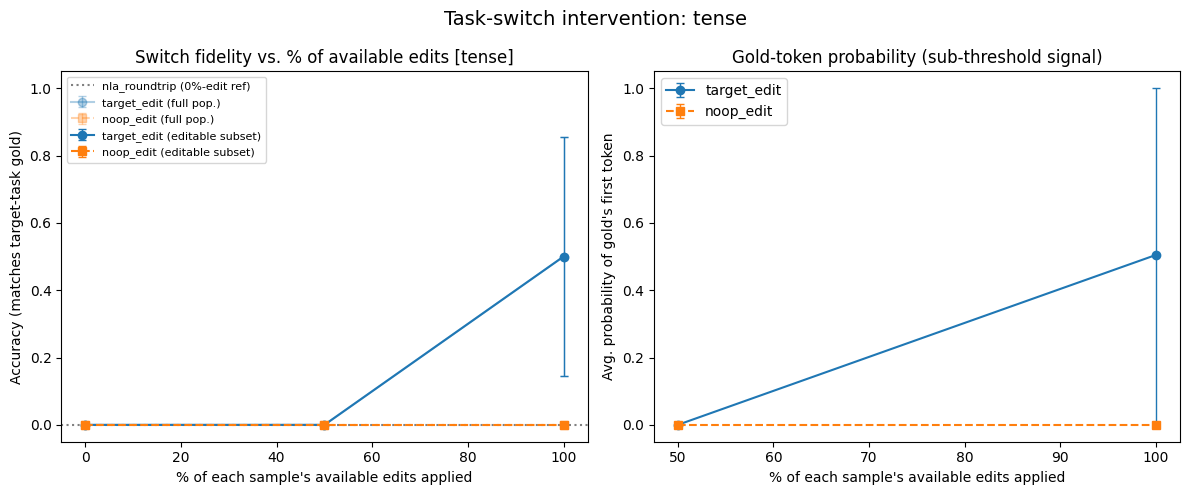

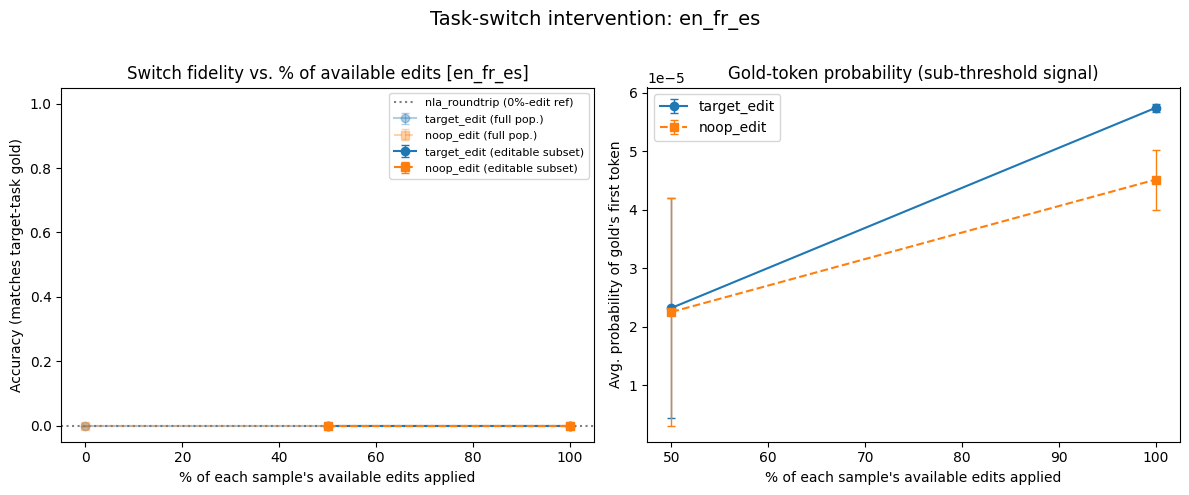

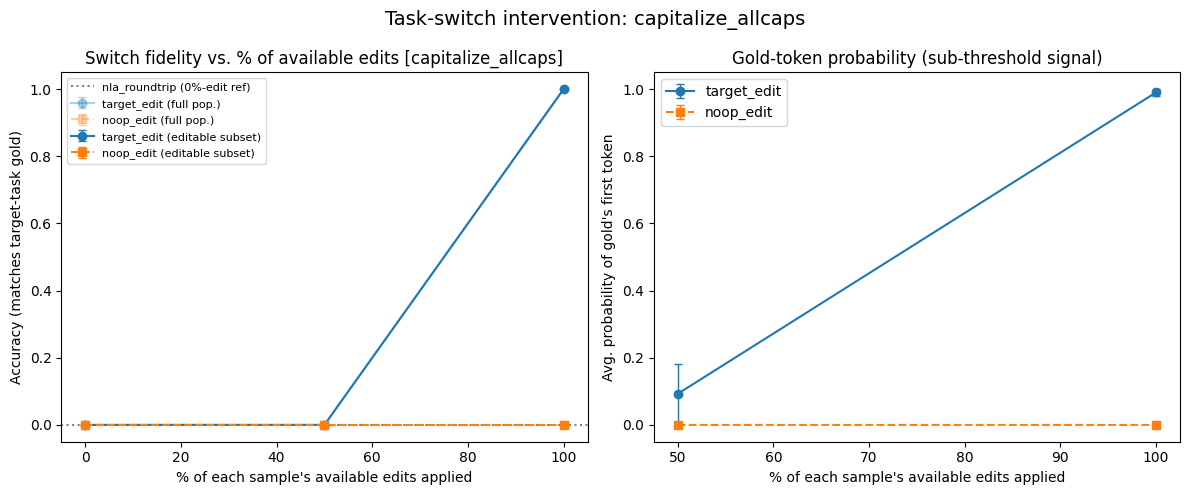

In [11]:
all_results = run_all_tasks(["tense", "en_fr_es", "capitalize_allcaps"], verbose=True)
for task_name, results in all_results.items():
    plot_sweep(task_name, results)

### Sample Based Analysis

In [12]:
all_thresholds = {}
all_summaries = {}
for task_name in ["tense", "en_fr_es", "capitalize_allcaps"]:
    print(f"\n{'#' * 70}\n# TASK: {task_name}\n{'#' * 70}")
    all_thresholds[task_name] = run_flip_threshold_batch(task_name, n_queries=N_PER_CONFIG, n_shots=4)
    all_summaries[task_name] = summarize_flip_thresholds(all_thresholds[task_name])


######################################################################
# TASK: tense
######################################################################
[tense] dropped 7 identity/degenerate records (199 usable)


flip-threshold [tense]: 100%|██████████| 2/2 [06:04<00:00, 182.24s/it]


n total              = 2
n no edits available = 0  (skipped -- nothing to evaluate)
n evaluable          = 2
flip_rate            = 0.000
n never flipped      = 2  (needed more edits than were available)
mean threshold_pct   = n/a
median threshold_pct = n/a

######################################################################
# TASK: en_fr_es
######################################################################
[en_fr_es] dropped 2167 identity/degenerate records (3857 usable)


flip-threshold [en_fr_es]: 100%|██████████| 2/2 [00:29<00:00, 14.71s/it]


n total              = 2
n no edits available = 2  (skipped -- nothing to evaluate)
n evaluable          = 0
flip_rate            = n/a
n never flipped      = 0  (needed more edits than were available)
mean threshold_pct   = n/a
median threshold_pct = n/a

######################################################################
# TASK: capitalize_allcaps
######################################################################


flip-threshold [capitalize_allcaps]: 100%|██████████| 2/2 [11:54<00:00, 357.42s/it]

n total              = 2
n no edits available = 0  (skipped -- nothing to evaluate)
n evaluable          = 2
flip_rate            = 1.000
n never flipped      = 0  (needed more edits than were available)
mean threshold_pct   = 64.9%  (of samples that flipped)
median threshold_pct = 68.8%


### Examples of Intervention

In [17]:
def save_example(results, task_name, f):
    # Use the 100% config -- after_explanation_full is guaranteed to be the
    # actual edited_text there (no separate computation needed to trust it).
    cfg100 = next(r for r in results if r["pct_edits_requested"] == 100)
    editable = [s for s in cfg100["samples"] if s.get("is_editable")]

    # Prefer a genuine flip (edit correct, noop still wrong) -- the clearest
    # illustration of the intervention actually doing something. Falls back
    # to any editable sample, then any sample at all, so this never errors
    # out even if nothing flipped in this particular random draw.
    flips = [s for s in editable if s.get("correct_edit") and not s.get("correct_noop")]
    example = (flips or editable or cfg100["samples"])[0] if cfg100["samples"] else None

    if example is None:
        text = f"[{task_name}] no samples found in the 100% config\n"
    else:
        text = (
            f"\n=== {task_name} ===\n"
            f"query: {example['query']!r}   target_gold: {example['target_gold']!r}\n"
            f"\nBEFORE:\n{example['before_explanation']}\n"
            f"\nAFTER (100% edit):\n{example['after_explanation_full']}\n"
            f"\npred_edit={example.get('pred_edit')!r}  correct_edit={example.get('correct_edit')}\n"
            f"pred_noop={example.get('pred_noop')!r}  correct_noop={example.get('correct_noop')}\n"
        )

    print(text)
    f.write(text)


with open("intervention_examples.txt", "w", encoding="utf-8") as f:
    for task_name, results in all_results.items():
        save_example(results, task_name, f)


=== tense ===
query: 'bent'   target_gold: 'will bend'

BEFORE:
Dictionary/word-lookup format: structured pattern of definitions and examples for "bent" with consistent grammar.

The phrase "past tense of bend: bent" establishes a list of verb forms, requiring a word completing the pattern "bent/bent" — the archaic past participle form.

Final token "be called be bent" ends a verb phrase ("bent or..."), immediately requiring a parallel structure like "bent" or "bent bent" to name the verb form, likely "bent" or "bent bowed" or "bent bowed" or "bent bended." — the word "bent" completing the idiom "bent/bent" for the verb.

AFTER (100% edit):
Dictionary/word-lookup format: structured pattern of definitions and examples for "will bend" with consistent grammar.

The phrase "past tense of bend: will bend" establishes a list of verb forms, requiring a word completing the pattern "will bend/will bend" — the archaic past participle form.

Final token "be called be will bend" ends a verb phras

Panel 1 — Tense-flip fidelity vs. achieved edit count: Accuracy (does the patched generation match the future-tense gold?) for tense_edit vs. noop_edit, plotted against the actual number of edits applied (not requested). The gray dotted line is the 0-edit NLA round-trip reference. This is the core result: if tense_edit accuracy rises above noop_edit and the baseline as edit count increases, that's evidence the edited verbalization is steering generation toward the future tense.

Panel 2 — Gold-token probability (sub-threshold signal): Average probability the model assigns to the gold future-tense word's first token (e.g. "will"), for tense_edit vs. noop_edit, read directly from logits rather than the decoded/argmax prediction. This catches cases where the edit shifts probability mass toward the correct answer without actually flipping the top-1 prediction — a more sensitive signal than accuracy alone, especially useful at small sample sizes.

Panel 3 — Predictions differ between edit and noop: Fraction of samples where tense_edit and noop_edit produce different generated text at all, regardless of correctness. This is the most sensitive behavioral signal in the set — it can be high even when accuracy is flat, showing the edit is having some effect on generation even if that effect doesn't land on the exact gold answer.

Panel 4 — NLA round-trip reconstruction error (baseline noise floor): ||h_orig - h_hat_plain|| / ||h_orig|| — how much the activation vector drifts just from the unedited encode→decode round trip (av() then ar()), with no tense edit involved. This is the noise floor: any edit-induced vector shift should be interpreted relative to this baseline level of reconstruction error.
- In principle, Panel 4 should be roughly flat (noisy, but with no systematic trend) as a function of edit count.

Panel 5 — Edit-induced vector shift (relative to noop): ||h_hat_edit - h_hat_noop|| / ||h_hat_noop|| — how far the edited-text reconstruction moves in vector space relative to the noop-text reconstruction, normalized by the noop vector's norm. Isolates the effect of the tense edit itself, since both h_hat_edit and h_hat_noop go through identical apply_future_edits processing except for whether the replacement is the future form or the original word.

Panel 6 — Edit-induced vector shift (vs. unedited reconstruction): ||h_hat_edit - h_hat_plain|| — absolute distance between the edited reconstruction and the original unedited reconstruction (not the noop control). Complements Panel 5 by showing the edit's effect against the plain baseline vector rather than against the noop control, useful for sanity-checking that the edit moves the vector at all

## Cleanup

Close the AV client's HTTP session and stop SGLang only if this notebook launched it. An AV server that was already running before the notebook is left untouched.


In [14]:
if "client" in globals() and hasattr(client, "_http"):
    client._http.close()
    print("Closed NLA client HTTP session")

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

if "sglang_proc" in globals() and sglang_proc is not None:
    sglang_proc.terminate()
    sglang_proc.wait(timeout=30)
    print("Stopped SGLang launched by this notebook")
else:
    print("No SGLang subprocess launched by this notebook")

# Optional final memory check:
# !nvidia-smi

Closed NLA client HTTP session
Stopped SGLang launched by this notebook
